## Setup and Data Loading
Import the necessary libraries and load the three job posting datasets. Ensure these CSV files are in the same directory as this notebook.



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set plotting style
sns.set_theme(style="whitegrid")

# Define file paths
files = {
    "LinkedIn Data Jobs": "data/unused_datasets/linkedin_data_jobs_dataset.csv",
    "Fake Job Postings": "data/unused_datasets/fake_job_postings.csv",
    "LinkedIn 2023-2024": "data/linkedin_job_postings_2023-2024.csv"
}

datasets = {}
for name, path in files.items():
    try:
        # Using low_memory=False to handle mixed types in large datasets
        datasets[name] = pd.read_csv(path, low_memory=False)
        print(f"✅ Successfully loaded: {name} ({datasets[name].shape[0]} rows, {datasets[name].shape[1]} columns)")
    except FileNotFoundError:
        print(f"❌ File not found: {path}. Please ensure it is in the same directory.")


✅ Successfully loaded: LinkedIn Data Jobs (123849 rows, 31 columns)
✅ Successfully loaded: Fake Job Postings (17880 rows, 18 columns)
✅ Successfully loaded: LinkedIn 2023-2024 (1048 rows, 10 columns)



## Column Names and Basic Structure
Inspect the columns available in each dataset to identify the relevant fields for job titles and job descriptions.



--- LinkedIn Data Jobs ---
Columns: job_id, company_name, title, description, max_salary, pay_period, location, company_id, views, med_salary, min_salary, formatted_work_type, applies, original_listed_time, remote_allowed, job_posting_url, application_url, application_type, expiry, closed_time, formatted_experience_level, skills_desc, listed_time, posting_domain, sponsored, work_type, currency, compensation_type, normalized_salary, zip_code, fips

--- Fake Job Postings ---
Columns: job_id, title, location, department, salary_range, company_profile, description, requirements, benefits, telecommuting, has_company_logo, has_questions, employment_type, required_experience, required_education, industry, function, fraudulent

--- LinkedIn 2023-2024 ---
Columns: id, title, company, location, link, source, date_posted, work_type, employment_type, description


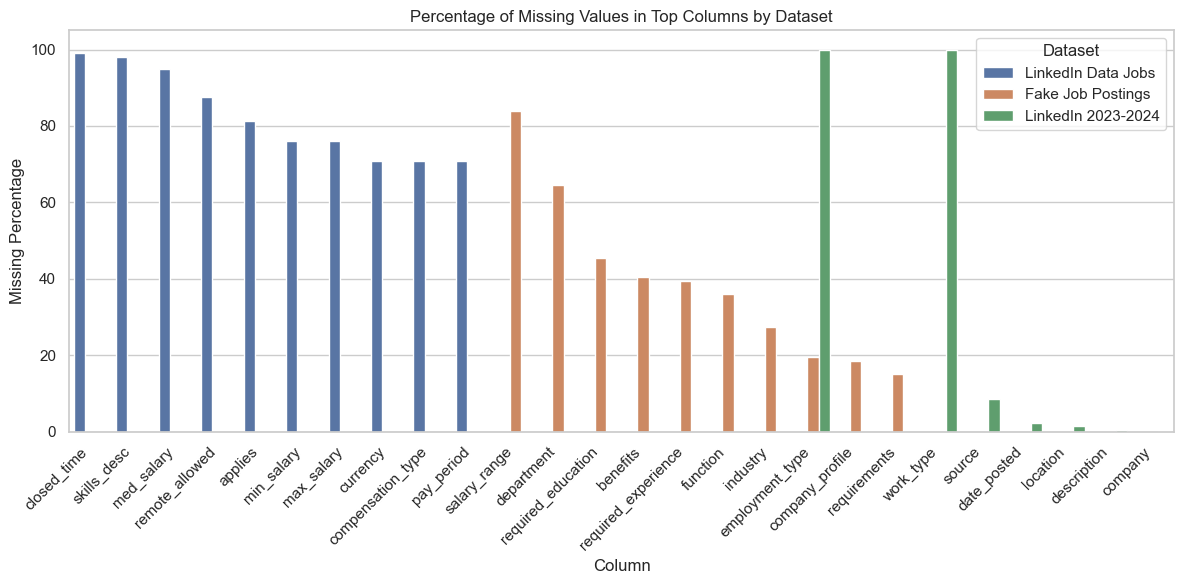

In [11]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print(f"Columns: {', '.join(df.columns.tolist())}")

# %% [markdown]
# ## Missing Values Analysis
# Identify how much data might be missing in key columns. High rates of missing descriptions or titles will negatively impact the skill-extraction pipelines.

# %%
missing_data = []

for name, df in datasets.items():
    missing_pct = (df.isnull().sum() / len(df)) * 100
    # Keep columns that have at least some missing values, or just the top 10
    missing_pct = missing_pct.sort_values(ascending=False).head(10)
    
    for col, pct in missing_pct.items():
        if pct > 0:
            missing_data.append({"Dataset": name, "Column": col, "Missing Percentage": pct})

missing_df = pd.DataFrame(missing_data)

if not missing_df.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(data=missing_df, x="Column", y="Missing Percentage", hue="Dataset")
    plt.xticks(rotation=45, ha='right')
    plt.title("Percentage of Missing Values in Top Columns by Dataset")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the datasets.")



## Unique Values for Job Titles
Determine the variety of job roles present. A dataset with higher variance might provide a more robust test for mapping unstructured text to standardized occupational tables.


In [12]:
def get_title_col(df):
    """Helper function to find the likely job title column."""
    cols = [c.lower() for c in df.columns]
    if 'title' in cols:
        return df.columns[cols.index('title')]
    elif 'job_title' in cols:
        return df.columns[cols.index('job_title')]
    return None

title_stats = []

for name, df in datasets.items():
    title_col = get_title_col(df)
    if title_col:
        unique_count = df[title_col].nunique()
        total_count = len(df[title_col].dropna())
        title_stats.append({
            "Dataset": name,
            "Total Valid Titles": total_count,
            "Unique Titles": unique_count,
            "Title Column Used": title_col
        })

stats_df = pd.DataFrame(title_stats)
display(stats_df)


,Dataset,Total Valid Titles,Unique Titles,Title Column Used
0,LinkedIn Data Jobs,123849,72521,title
1,Fake Job Postings,17880,11231,title
2,LinkedIn 2023-2024,1048,523,title


## Top 10 Job Title Distributions
Visualize the most frequent job titles to see if the dataset is heavily skewed toward specific roles or broadly distributed.

C:\Users\oi12b\AppData\Local\Temp\ipykernel_10080\1854620958.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_titles.values, y=top_titles.index, ax=ax, palette="viridis")
C:\Users\oi12b\AppData\Local\Temp\ipykernel_10080\1854620958.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_titles.values, y=top_titles.index, ax=ax, palette="viridis")
C:\Users\oi12b\AppData\Local\Temp\ipykernel_10080\1854620958.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_titles.values, y=top_titles.index, ax=ax, palette="viridis")


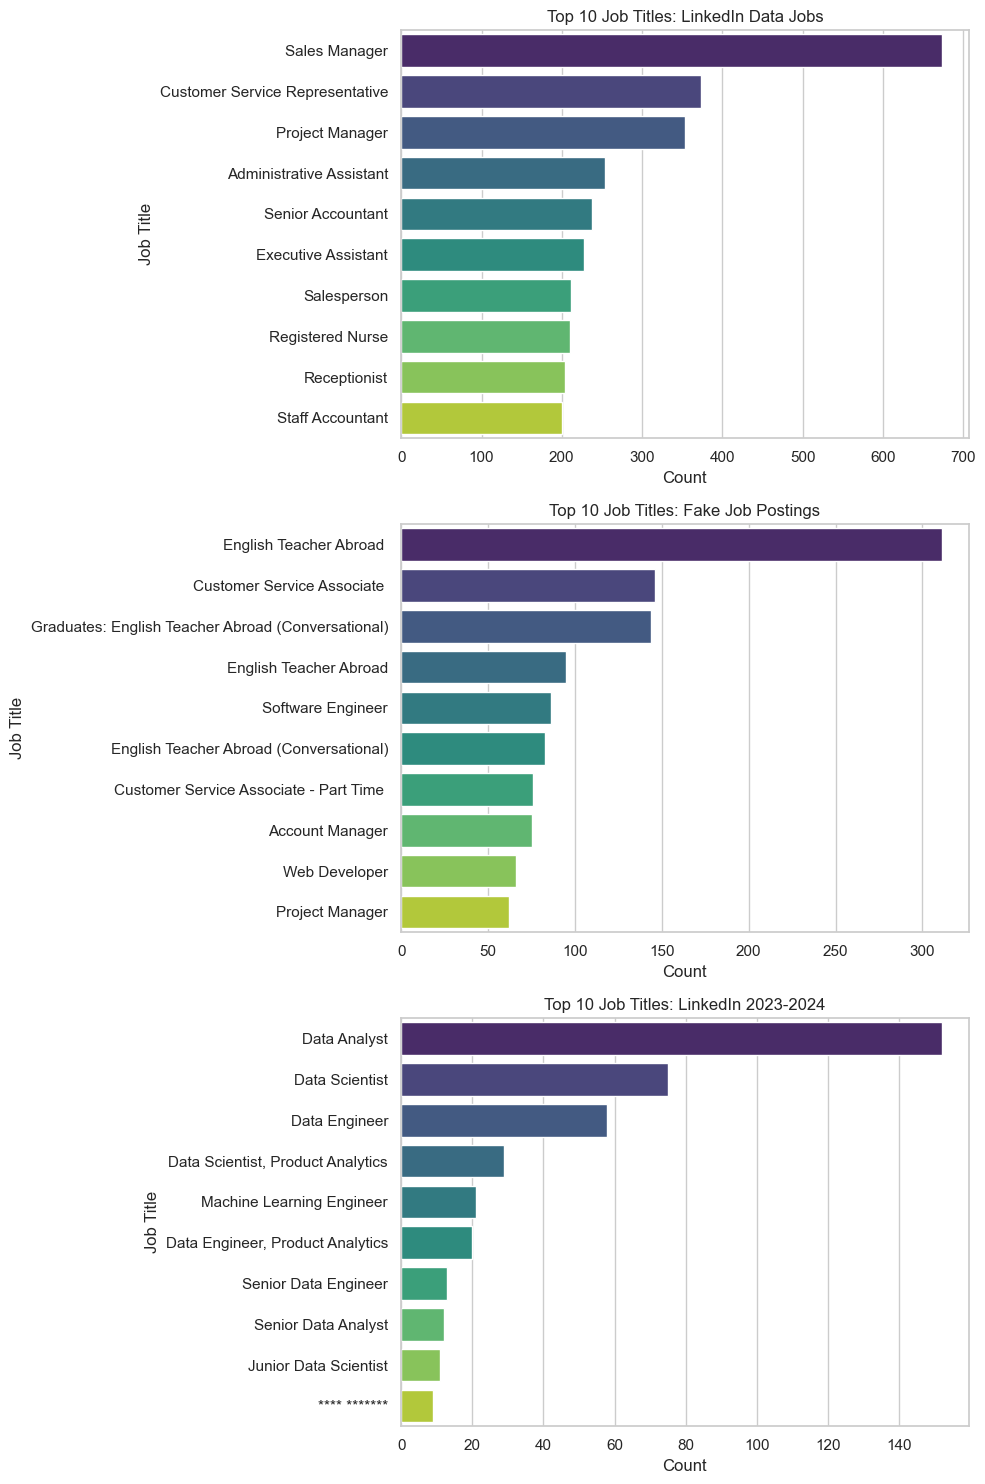

In [13]:
fig, axes = plt.subplots(len(datasets), 1, figsize=(10, 5 * len(datasets)))

for ax, (name, df) in zip(axes, datasets.items()):
    title_col = get_title_col(df)
    if title_col:
        top_titles = df[title_col].value_counts().head(10)
        sns.barplot(x=top_titles.values, y=top_titles.index, ax=ax, palette="viridis")
        ax.set_title(f"Top 10 Job Titles: {name}")
        ax.set_xlabel("Count")
        ax.set_ylabel("Job Title")

plt.tight_layout()
plt.show()


## Job Description Text Length Distribution
The richness of the job description is critical for NLP and skill keyword extraction. This calculates the word count of the descriptions and visualizes the distribution.

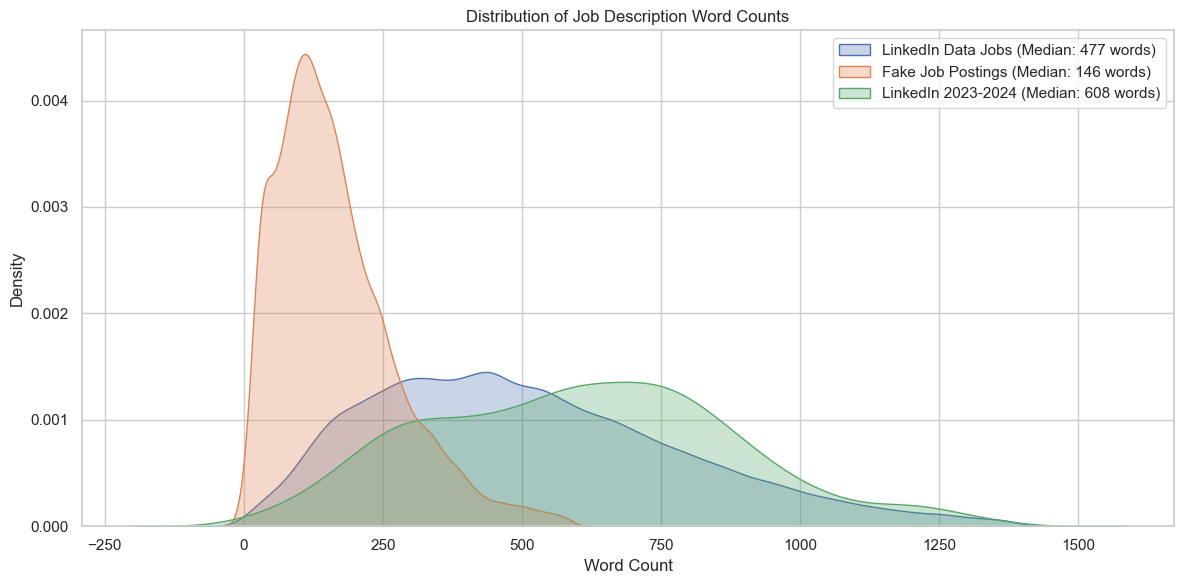

In [14]:
def get_desc_col(df):
    """Helper function to find the likely job description column."""
    cols = [c.lower() for c in df.columns]
    if 'description' in cols:
        return df.columns[cols.index('description')]
    elif 'job_description' in cols:
        return df.columns[cols.index('job_description')]
    return None

plt.figure(figsize=(12, 6))

for name, df in datasets.items():
    desc_col = get_desc_col(df)
    if desc_col:
        # Calculate approximate word count for valid descriptions
        word_counts = df[desc_col].dropna().astype(str).apply(lambda x: len(x.split()))
        
        # Filter out extreme outliers for a cleaner plot (e.g., > 99th percentile)
        q99 = word_counts.quantile(0.99)
        filtered_counts = word_counts[word_counts <= q99]
        
        sns.kdeplot(filtered_counts, label=f"{name} (Median: {word_counts.median():.0f} words)", fill=True, alpha=0.3)

plt.title("Distribution of Job Description Word Counts")
plt.xlabel("Word Count")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()